In [5]:
import pandas as pd

COLS = ["time", "s1", "s2", "s3", "s4", "s5", "s6"]

df = pd.read_csv("AReM/bending1/dataset1.csv", comment="#", header=None, names=COLS)
df = df.drop(columns="time")   # keep only the 6 series
df.head()

,s1,s2,s3,s4,s5,s6
0,39.25,0.43,22.75,0.43,33.75,1.3
1,39.25,0.43,23.00,0.00,33.00,0.0
2,39.25,0.43,23.25,0.43,33.00,0.0
3,39.50,0.50,23.00,0.71,33.00,0.0
4,39.50,0.50,24.00,0.00,33.00,0.0


**Answers to a and b here**

In [6]:
from pathlib import Path
import pandas as pd

DATA_DIR = Path("AReM")
COLS = ["time", "s1", "s2", "s3", "s4", "s5", "s6"]

def load_instance(path):
    """Read one file into a table of the 6 series (480 rows x 6 columns)."""
    rows = []
    with open(path) as fh:
        for line in fh:
            line = line.strip()
            if not line or line.startswith("#"):    # skip blank and header lines
                continue
            parts = line.replace(",", " ").split()  # works for commas or spaces
            if len(parts) == len(COLS):
                rows.append(parts)
    return pd.DataFrame(rows, columns=COLS).astype(float).drop(columns="time")

records = []
for folder in sorted(DATA_DIR.iterdir()):
    if not folder.is_dir():
        continue
    activity = folder.name
    for f in folder.glob("dataset*.csv"):
        num = int(f.stem.replace("dataset", ""))
        test_ids = {1, 2} if activity in ("bending1", "bending2") else {1, 2, 3}
        records.append({"activity": activity,
                        "dataset": num,
                        "split": "test" if num in test_ids else "train",
                        "data": load_instance(f)})

In [7]:
print(len(records))                                           # expect 88
print(pd.Series([r["split"] for r in records]).value_counts())  # expect train 69, test 19
print(records[0]["activity"], records[0]["data"].shape)         # expect (480, 6)

88
train    69
test     19
Name: count, dtype: int64
bending1 (480, 6)


**Test and train data separated**

**Ans to c(i)**

min, max, range, mean, median, standard deviation, variance, quartiles, IQR, skewness, kurtosis, RMS, and zero-crossing rate.

**Ans to c(ii)**

In [8]:
x = records[0]["data"]       # a 480 x 6 table

x["s1"].min()
x["s1"].max()
x["s1"].mean()
x["s1"].median()
x["s1"].std()
x["s1"].quantile(0.25)       # first quartile
x["s1"].quantile(0.75)       # third quartile

np.float64(42.0)

In [10]:
STATS = {"min": "min", "max": "max", "mean": "mean",
         "median": "median", "std": "std", "q1": 0.25, "q3": 0.75}

def extract(x):
    """One instance (480x6 table) -> one row of 42 features."""
    out = {}
    for j, name in enumerate(["s1", "s2", "s3", "s4", "s5", "s6"], start=1):
        col = x[name]
        for stat, how in STATS.items():
            out[f"{stat}{j}"] = col.quantile(how) if stat in ("q1", "q3") else getattr(col, how)()
    return out

feat = pd.DataFrame([extract(r["data"]) for r in records])
feat.insert(0, "activity", [r["activity"] for r in records])
feat.insert(1, "split", [r["split"] for r in records])

feat.shape          # (88, 44)  -> 42 features + activity + split
feat.head()
pd.set_option("display.max_rows", None)
feat

,activity,split,min1,max1,mean1,median1,std1,q11,q31,min2,...,std5,q15,q35,min6,max6,mean6,median6,std6,q16,q36
0,bending1,test,37.25,45.00,40.624792,40.500,1.476967,39.2500,42.0000,0.0,...,2.188449,33.0000,36.0000,0.00,1.92,0.570583,0.430,0.582915,0.0000,1.3000
1,bending1,test,38.00,45.67,42.812812,42.500,1.435550,42.0000,43.6700,0.0,...,1.995255,32.0000,34.5000,0.00,3.11,0.571083,0.430,0.601010,0.0000,1.3000
2,bending1,train,35.00,47.40,43.954500,44.330,1.558835,43.0000,45.0000,0.0,...,1.999604,35.3625,36.5000,0.00,1.79,0.493292,0.430,0.513506,0.0000,0.9400
3,bending1,train,33.00,47.75,42.179812,43.500,3.670666,39.1500,45.0000,0.0,...,3.849448,30.4575,36.3300,0.00,2.18,0.613521,0.500,0.524317,0.0000,1.0000
4,bending1,train,33.00,45.75,41.678063,41.750,2.243490,41.3300,42.7500,0.0,...,2.411026,28.4575,31.2500,0.00,1.79,0.383292,0.430,0.389164,0.0000,0.5000
5,bending1,train,37.00,48.00,43.454958,43.250,1.386098,42.5000,45.0000,0.0,...,2.488862,22.2500,24.0000,0.00,5.26,0.679646,0.500,0.622534,0.4300,0.8700
6,bending1,train,36.25,48.00,43.969125,44.500,1.618364,43.3100,44.6700,0.0,...,3.318301,20.5000,23.7500,0.00,2.96,0.555312,0.490,0.487826,0.0000,0.8300
7,bending2,test,12.75,51.00,24.562958,24.250,3.737514,23.1875,26.5000,0.0,...,3.693786,20.5000,27.0000,0.00,4.97,0.700188,0.500,0.693720,0.4300,0.8700
8,bending2,test,0.00,42.75,27.464604,28.000,3.583582,25.5000,30.0000,0.0,...,5.053642,15.0000,20.7500,0.00,6.76,1.122125,0.830,1.012342,0.4700,1.3000
9,bending2,train,21.00,50.00,32.586208,33.000,6.238143,26.1875,34.5000,0.0,...,5.032424,17.6700,23.5000,0.00,13.61,1.162042,0.830,1.332980,0.4700,1.3000


**Ans to c(iii)**

In [12]:
import numpy as np
from scipy.stats import bootstrap

feat_cols = [c for c in feat.columns if c not in ("activity", "split", "instance")]

rows = []
for c in feat_cols:
    x = feat[c].to_numpy()
    s = np.std(x)
    if np.ptp(x) == 0:                     # constant feature (min2, min4 are all 0): CI is just [0, 0]
        low, high = 0.0, 0.0
    else:
        res = bootstrap((x,), np.std, confidence_level=0.90,
                        n_resamples=5000, random_state=0)
        low, high = res.confidence_interval.low, res.confidence_interval.high
    rows.append({"feature": c, "std": s, "ci_low": low, "ci_high": high})

ci = pd.DataFrame(rows)
ci.round(3)

,feature,std,ci_low,ci_high
0,min1,9.515,8.471,11.059
1,max1,4.369,3.519,5.459
2,mean1,5.305,4.817,5.999
3,median1,5.409,4.904,6.128
4,std1,1.762,1.601,1.999
5,q11,6.119,5.653,6.736
6,q31,5.110,4.460,5.966
7,min2,0.000,0.000,0.000
8,max2,5.034,4.675,5.435
9,mean2,1.565,1.407,1.708


**Plotting the confidence intervals**

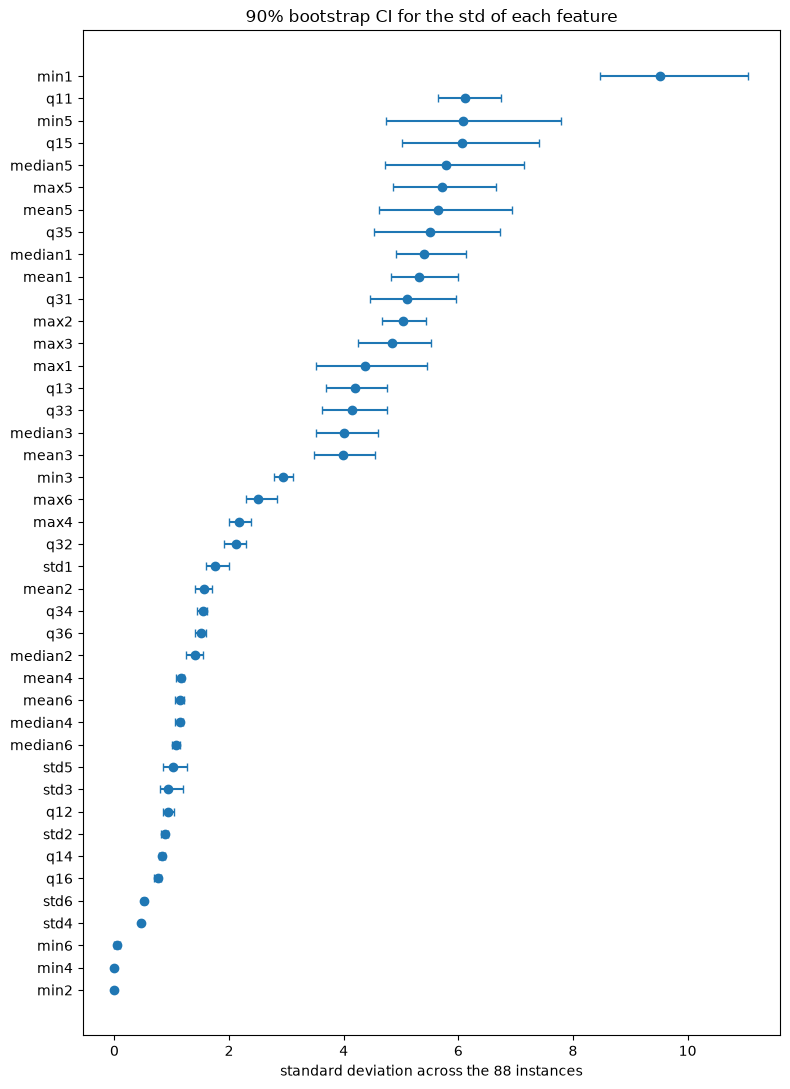

In [14]:
from matplotlib import pyplot as plt
ci_sorted = ci.sort_values("std")          # smallest std at the bottom

plt.figure(figsize=(8, 11))
plt.errorbar(x=ci_sorted["std"],
             y=ci_sorted["feature"],
             xerr=[ci_sorted["std"] - ci_sorted["ci_low"],      # distance down to ci_low
                   ci_sorted["ci_high"] - ci_sorted["std"]],    # distance up to ci_high
             fmt="o", capsize=3)
plt.xlabel("standard deviation across the 88 instances")
plt.title("90% bootstrap CI for the std of each feature")
plt.tight_layout()
plt.show()

c(iv) I select the maximum values of the three variance channels (max2, max4, and max6) as the three most important features. Although the average-RSS channels show greater differences between instances, these differences mainly reflect the sensors' positions relative to each other rather than physical activity. This helps distinguish static activities, such as sitting and lying down, but provides limited information about movement. In contrast, the variance channels capture changes in movement. Their values remain low during static activities and increase during activities such as walking and cycling, making them more useful for classification. I chose the maximum instead of the mean because the mean can smooth out short bursts of movement, while the maximum captures these peaks.

2.

(a) We expect the cubic’s training RSS to be lower (or at worst equal). The cubic model nests the linear one, so it has extra flexibility to fit the noise in the training data and will reduce training RSS even though the truth is linear.

(b) We expect the linear model’s test RSS to be lower. Cubic model can overfit here.

(c) We expect the cubic’s training RSS to be lower (or at worst equal), as in (a). More flexible models always fit the training data at least as well regardless of the true relationship, so a nested larger model cannot have higher training RSS.

(d) There is not enough information to tell. I